In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
)

tipos_noaa = carregar_noaa_por_tipo()
ow_mar = tipos_noaa["Ocean water"]
print(f"Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): {len(ow_mar)} pontos")

Ocean water (0,02-5,0 mm, GEBCO <= 0 no mar): 14363 pontos


In [2]:
# 1. Segmentar o globo em porcoes de terra (externos/GebcoCutter) e rodar IPBA + CCA em cada porcao
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(ow_mar, max_r_km=50.0)

bacias_por_porcao = []
for val in porcoes_ativas:
    df_porcao = processar_ou_carregar_porcao(val, info, arr, label)
    if len(df_porcao) > 0:
        bacias_por_porcao.append(df_porcao)

df_bacias_globais = pd.concat(bacias_por_porcao, ignore_index=True)
df_bacias_principais = df_bacias_globais[df_bacias_globais["area_km2"] >= 100.0].reset_index(drop=True)
print(f"Porcoes processadas: {len(porcoes_ativas)} | Total bacias: {len(df_bacias_globais)} | Bacias >= 100 km2: {len(df_bacias_principais)}")

Porcoes processadas: 1061 | Total bacias: 179718 | Bacias >= 100 km2: 20168


In [3]:
# 2. Media no raio fixo do sink e juncao APENAS das bacias que tem valor no sink
bacias_r22 = media_por_sink_raio(df_bacias_principais, ow_mar, r_km=22.0)
bacias_r5 = media_por_sink_raio(df_bacias_principais, ow_mar, r_km=5.0)

res_r22_conc = ajustar_lei_potencia(bacias_r22, "total_population", "mp_mean")
res_r22_flux = ajustar_lei_potencia(bacias_r22, "total_population", "flux")
res_r5_urb = ajustar_lei_potencia(bacias_r5, "urban_population", "mp_mean")

print(f"R = 22 km (Pop. Bacia x Media MP): N = {res_r22_conc['N']}, beta = {res_r22_conc['beta']:+.2f}, R2 = {res_r22_conc['r2_pct']:.1f}%, R2_bins = {res_r22_conc['r2_bins_pct']:.1f}%, p = {res_r22_conc['p_value']:.2e}")
print(f"R = 22 km (Pop. Bacia x Fluxo):    N = {res_r22_flux['N']}, beta = {res_r22_flux['beta']:+.2f}, R2 = {res_r22_flux['r2_pct']:.1f}%, p = {res_r22_flux['p_value']:.2e}")
print(f"R* = 5 km (Pop. Urbana x Media MP): N = {res_r5_urb['N']}, beta = {res_r5_urb['beta']:+.2f}, R2 = {res_r5_urb['r2_pct']:.1f}%, p = {res_r5_urb['p_value']:.2e}")

R = 22 km (Pop. Bacia x Media MP): N = 624, beta = +0.35, R2 = 14.1%, R2_bins = 86.2%, p = 2.25e-22
R = 22 km (Pop. Bacia x Fluxo):    N = 624, beta = +0.52, R2 = 25.3%, p = 2.88e-41
R* = 5 km (Pop. Urbana x Media MP): N = 49, beta = +0.70, R2 = 33.3%, p = 1.44e-05


In [4]:
# 3. Testar raios de 1 a 22 km ate achar o melhor resultado
linhas_r = []
for r_km in range(1, 23):
    df_r = media_por_sink_raio(df_bacias_principais, ow_mar, r_km=r_km)
    st_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
    st_t = ajustar_lei_potencia(df_r, "total_population", "mp_mean")
    linhas_r.append({"R_km": r_km, "N_urb": st_u["N"], "beta_urb": st_u["beta"], "R2_urb_pct": st_u["r2_pct"], "N_tot": st_t["N"], "beta_tot": st_t["beta"], "R2_tot_pct": st_t["r2_pct"]})

df_varredura = pd.DataFrame(linhas_r)
print(df_varredura[df_varredura["R_km"] >= 3].round(2).to_string(index=False))

 R_km  N_urb  beta_urb  R2_urb_pct  N_tot  beta_tot  R2_tot_pct
    3     15      0.37        9.51     21      0.53       20.09
    4     31      0.45       18.03     42      0.48       26.85
    5     49      0.70       33.27     65      0.54       22.85
    6     64      0.59       22.61     90      0.56       20.22
    7     81      0.54       17.77    120      0.52       17.71
    8     95      0.48       11.64    148      0.52       17.82
    9    105      0.47       11.47    171      0.50       17.11
   10    117      0.50       11.85    199      0.54       17.39
   11    128      0.50       11.89    226      0.49       14.34
   12    141      0.48       11.53    259      0.43       12.54
   13    157      0.52       13.30    300      0.44       15.07
   14    167      0.48       11.64    321      0.43       15.01
   15    188      0.47       11.51    356      0.42       14.15
   16    207      0.45       11.26    389      0.38       12.94
   17    225      0.45       11.39    42

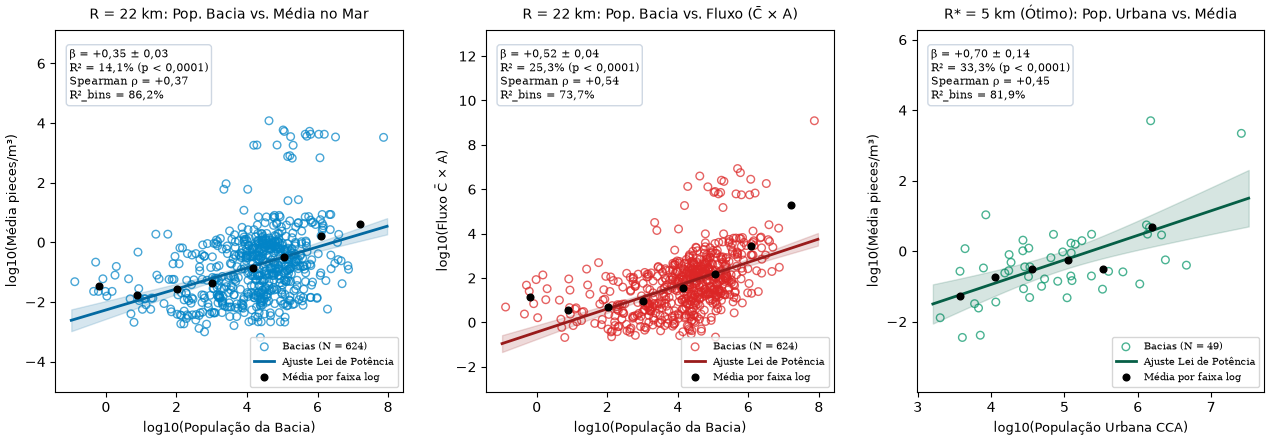

In [5]:
# 4. Grafico da Lei de Potencia (correlacoes positivas em R = 22 km e R* = 5 km)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.6, 4.7), gridspec_kw={"wspace": 0.24})

plotar_lei_potencia(ax1, bacias_r22, "total_population", "mp_mean", "R = 22 km: Pop. Bacia vs. Média no Mar", "log10(População da Bacia)", "log10(Média pieces/m³)", "#0284c7", "#0369a1")
plotar_lei_potencia(ax2, bacias_r22, "total_population", "flux", "R = 22 km: Pop. Bacia vs. Fluxo (C̄ × A)", "log10(População da Bacia)", "log10(Fluxo C̄ × A)", "#dc2626", "#991b1b")
plotar_lei_potencia(ax3, bacias_r5, "urban_population", "mp_mean", "R* = 5 km (Ótimo): Pop. Urbana vs. Média", "log10(População Urbana CCA)", "log10(Média pieces/m³)", "#059669", "#065f46")

plt.show()